# Week 3: Data Cleaning and Preprocessing Pipeline Development
## Project: Review-Informed Skincare Product Discovery Using NLP and Data Analytics

**Dataset:** `jhan21/amazon-beauty-reviews-dataset` on Hugging Face  
**Working sample:** First 10,000 rows (reproducible sample used for the earlier Week 2 exploration)  
**Purpose:** Build, execute, audit, and document a reproducible cleaning pipeline before downstream EDA and NLP.

> Scope note: The source is the broad **All Beauty** category, not a skincare-only dataset. Do not interpret the sample as representative of skincare products until product metadata/category filtering is completed.

## 1. Learning objectives and pipeline design

This notebook demonstrates:
1. Loading and profiling the raw data without overwriting it.
2. Checking schema, data types, missingness, duplicates, invalid values, and text quality.
3. Applying justified cleaning decisions rather than deleting records automatically.
4. Creating transparent flags for outliers and low-information reviews.
5. Producing a cleaned master dataset, an NLP-ready subset, a quality audit, and a cleaning log.

**Tools and rationale**
- **Pandas:** tabular inspection, missing-value handling, deduplication, type conversion, and exports.
- **NumPy:** conditional flags and numerical operations.
- **Regular expressions (`re`):** conservative whitespace and text normalization.
- **Matplotlib:** optional diagnostic plots; useful for explaining skew and outliers.

The pipeline preserves the raw source and documents every transformation so another analyst can reproduce it.

## 2. Environment and imports

If needed, install dependencies in the active environment:

```bash
pip install pandas numpy matplotlib fsspec huggingface_hub
```

The dataset CSV is approximately 232 MB. Reading only 10,000 rows keeps this Week 3 exercise practical. To process the full file later, remove `nrows=10_000` after confirming available memory and storage.

In [1]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
from pathlib import Path
from datetime import datetime

pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 120)

RANDOM_SEED = 42
SAMPLE_SIZE = 10_000

## 3. Load the dataset

The first option reads from the Hugging Face dataset using the same `hf://` style used in the earlier analysis. If the download is already saved locally, set `LOCAL_CSV` to its path and use that instead.

Do not use a random sample before preserving the original row order if you need to reproduce the exact earlier Week 2 sample.

In [2]:
DATASET_URI = "hf://datasets/jhan21/amazon-beauty-reviews-dataset/amazon_beauty_reviews_dataset.csv"
LOCAL_CSV = None  # Example: "amazon_beauty_reviews_dataset.csv"

if LOCAL_CSV and Path(LOCAL_CSV).exists():
    df_raw = pd.read_csv(LOCAL_CSV, nrows=SAMPLE_SIZE)
else:
    df_raw = pd.read_csv(DATASET_URI, nrows=SAMPLE_SIZE)

print("Raw sample shape:", df_raw.shape)
display(df_raw.head())

Raw sample shape: (10000, 10)


,rating,title,text,images,asin,parent_asin,user_id,timestamp,helpful_vote,verified_purchase
0,5,Such a lovely scent but not overpowering.,"This spray is really nice. It smells really good, goes on really fine, and does the trick. I will say it feels like ...",[],B00YQ6X8EO,B00YQ6X8EO,AGKHLEW2SOWHNMFQIJGBECAF7INQ,2020-05-05 14:08:48.923,0,True
1,4,Works great but smells a little weird.,"This product does what I need it to do, I just wish it was odorless or had a soft coconut smell. Having my head smel...",[],B081TJ8YS3,B081TJ8YS3,AGKHLEW2SOWHNMFQIJGBECAF7INQ,2020-05-04 18:10:55.070,1,True
2,5,Yes!,"Smells good, feels great!",[],B07PNNCSP9,B097R46CSY,AE74DYR3QUGVPZJ3P7RFWBGIX7XQ,2020-05-16 21:41:06.052,2,True
3,1,Synthetic feeling,Felt synthetic,[],B09JS339BZ,B09JS339BZ,AFQLNQNQYFWQZPJQZS6V3NZU4QBQ,2022-01-28 18:13:50.220,0,True
4,5,A+,Love it,[],B08BZ63GMJ,B08BZ63GMJ,AFQLNQNQYFWQZPJQZS6V3NZU4QBQ,2020-12-30 10:02:43.534,0,True


## 4. Initial data profiling

The published dataset card describes review fields including rating, title, text, images, ASIN, parent ASIN, user ID, timestamp, helpful votes, and verified-purchase status. The notebook checks the actual loaded file instead of assuming the schema is identical to the documentation.

In [3]:
print("Columns:", df_raw.columns.tolist())
print("\nData types:")
display(df_raw.dtypes.to_frame("data_type"))

print("\nMissing values:")
missing_before = df_raw.isna().sum().sort_values(ascending=False)
display(missing_before.to_frame("missing_count"))

print("\nDuplicate full rows:", int(df_raw.duplicated().sum()))
print("\nDescriptive statistics:")
display(df_raw.describe(include="all").T)

Columns: ['rating', 'title', 'text', 'images', 'asin', 'parent_asin', 'user_id', 'timestamp', 'helpful_vote', 'verified_purchase']

Data types:


,data_type
rating,int64
title,str
text,str
images,str
asin,str
parent_asin,str
user_id,str
timestamp,str
helpful_vote,int64
verified_purchase,bool



Missing values:


,missing_count
title,1
text,1
rating,0
images,0
asin,0
parent_asin,0
user_id,0
timestamp,0
helpful_vote,0
verified_purchase,0



Duplicate full rows: 13

Descriptive statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
rating,10000.0,NaN,NaN,NaN,4.1183,1.295405,1.0,4.0,5.0,5.0,5.0
title,9999,7890,Five Stars,528,NaN,NaN,NaN,NaN,NaN,NaN,NaN
text,9999,9769,Love it,17,NaN,NaN,NaN,NaN,NaN,NaN,NaN
images,10000,919,[],9078,NaN,NaN,NaN,NaN,NaN,NaN,NaN
asin,10000,7218,B007IAE5WY,34,NaN,NaN,NaN,NaN,NaN,NaN,NaN
parent_asin,10000,7067,B085BB7B1M,34,NaN,NaN,NaN,NaN,NaN,NaN,NaN
user_id,10000,6585,AG73BVBKUOH22USSFJA5ZWL7AKXA,165,NaN,NaN,NaN,NaN,NaN,NaN,NaN
timestamp,10000,9987,2015-09-25 22:07:06.000,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
helpful_vote,10000.0,NaN,NaN,NaN,0.949,5.722908,0.0,0.0,0.0,1.0,430.0
verified_purchase,10000,2,True,7128,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 5. Preserve the raw data and create a working copy

All cleaning is performed on `df`. `df_raw` remains unchanged and is used for before/after comparisons. This prevents accidental loss of evidence about the source data.

In [4]:
df = df_raw.copy(deep=True)
cleaning_log = []

def log_step(step, issue, action, rationale):
    cleaning_log.append({
        "step": step,
        "issue_or_check": issue,
        "action_taken": action,
        "rationale": rationale
    })

## 6. Standardize column names and inspect expected fields

Column names are normalized to lowercase snake_case. Missing expected columns are reported rather than silently fabricated.

In [5]:
df.columns = (
    df.columns.astype(str)
      .str.strip()
      .str.lower()
      .str.replace(r"[^a-z0-9]+", "_", regex=True)
      .str.strip("_")
)

expected_columns = [
    "rating", "title", "text", "images", "asin", "parent_asin",
    "user_id", "timestamp", "helpful_vote", "verified_purchase"
]
missing_columns = [c for c in expected_columns if c not in df.columns]
print("Expected columns missing from loaded file:", missing_columns)

log_step(
    "Column standardization",
    "Column labels may contain inconsistent capitalization or spacing",
    "Normalized labels to lowercase snake_case",
    "Consistent names reduce coding errors and make the pipeline reusable."
)

Expected columns missing from loaded file: []


## 7. Missing values: assess, decide, and implement

Do not drop every row containing a missing value. The correct action depends on the field:
- `title`: fill missing values with an empty string because the review body may still contain useful information.
- `images`: if no image was uploaded (missing, blank, or an empty-list value), use the readable label `No image uploaded` instead of leaving `NaN`.
- `text`: retain a missing value in the master dataset, but exclude empty review bodies from the NLP-ready subset.
- `rating`: do not invent a rating; flag missing/invalid ratings and exclude them from rating-based analysis.
- identifiers and metadata: retain where possible; report missingness and avoid fabricating IDs.

Empty strings and whitespace-only strings are treated as missing for text-quality checks.

In [6]:
text_columns = [c for c in ["title", "text"] if c in df.columns]
for col in text_columns:
    df[col] = df[col].astype("string").str.strip()
    df[col] = df[col].replace(r"^\s*$", pd.NA, regex=True)

missing_before_handling = df.isna().sum()

if "title" in df.columns:
    df["title"] = df["title"].fillna("")

# Replace missing image uploads with a readable label instead of NaN.
# This handles null values, blank strings, and common empty-list representations.
if "images" in df.columns:
    no_image_values = {"", "[]", "nan", "none", "null"}
    images_missing = (
        df["images"].isna()
        | df["images"].astype("string").str.strip().str.lower().isin(no_image_values)
    )
    no_image_count = int(images_missing.sum())
    df.loc[images_missing, "images"] = "No image uploaded"
    print("Records with no image uploaded:", no_image_count)
else:
    no_image_count = None
    print("The source dataset does not contain an images column.")

log_step(
    "Missing values",
    "Missing or blank review titles and bodies",
    "Filled missing title with empty string; replaced absent image values with 'No image uploaded'; retained missing review body for audit and excluded it from NLP subset",
    "A missing title does not make an otherwise complete review unusable. The image label makes absent uploads explicit instead of displaying NaN. Missing review text cannot support text analysis."
)

display(pd.DataFrame({
    "missing_before": missing_before_handling,
    "missing_after_title_handling": df.isna().sum()
}))

Records with no image uploaded: 9078


,missing_before,missing_after_title_handling
rating,0,0
title,1,0
text,2,2
images,0,0
asin,0,0
parent_asin,0,0
user_id,0,0
timestamp,0,0
helpful_vote,0,0
verified_purchase,0,0


## 8. Duplicate detection

Exact duplicate rows and duplicate review identifiers are checked separately. If a stable review identifier exists, duplicate IDs are removed by retaining the first occurrence, while the number removed is logged. Exact duplicates are also checked after standardization.

In [7]:
# Check exact duplicate rows and a stable review identifier separately.
# This source schema does not contain a review_id column.
# user_id identifies a reviewer, not an individual review, so it must not be used for deduplication.

exact_duplicates = int(df.duplicated().sum())
id_col = "review_id" if "review_id" in df.columns else None

if id_col:
    duplicate_review_ids = int(df[id_col].duplicated().sum())
    before = len(df)
    df = df.drop_duplicates(subset=[id_col], keep="first").copy()
    removed_id_duplicates = before - len(df)
else:
    duplicate_review_ids = None
    removed_id_duplicates = 0
    print("No review_id column is available; user_id was not used as a review identifier.")

before_exact = len(df)
df = df.drop_duplicates().copy()
removed_exact_duplicates = before_exact - len(df)

log_step(
    "Duplicate handling",
    f"{exact_duplicates} exact duplicate rows found; "
    + ("review_id duplicates checked" if id_col else "no stable review_id field is available"),
    f"Removed {removed_id_duplicates} duplicate review IDs and {removed_exact_duplicates} exact duplicate rows",
    "Exact duplicate rows can overweight repeated feedback. user_id identifies a reviewer and is not a unique review key."
)

print("Exact duplicate rows detected before cleaning:", exact_duplicates)
print("Duplicate review identifiers:", duplicate_review_ids)
print("Exact duplicate rows removed:", removed_exact_duplicates)


No review_id column is available; user_id was not used as a review identifier.
Exact duplicate rows detected before cleaning: 13
Duplicate review identifiers: None
Exact duplicate rows removed: 13


## 9. Validate rating values

Ratings should be numeric and within the documented 1–5 range. Invalid values are flagged and not silently converted into a valid rating. A valid-rating flag is retained for transparent filtering.

In [8]:
if "rating" in df.columns:
    df["rating"] = pd.to_numeric(df["rating"], errors="coerce")
    df["invalid_rating"] = df["rating"].isna() | ~df["rating"].between(1, 5)
else:
    df["invalid_rating"] = True

invalid_rating_count = int(df["invalid_rating"].sum())
log_step(
    "Rating validation",
    "Ratings may be missing, non-numeric, or outside the 1–5 scale",
    "Converted ratings to numeric and flagged missing/out-of-range values",
    "Rating-based analysis requires valid values; invalid ratings are excluded only from rating-dependent analysis."
)
print("Invalid or missing ratings:", invalid_rating_count)

Invalid or missing ratings: 0


## 10. Parse timestamps and validate dates

The dataset page describes a timestamp field, while the downloadable CSV may serialize it as a readable date string or another representation. The parser handles common cases and preserves the original `timestamp` field. Failed conversions are flagged.

In [9]:
if "timestamp" in df.columns:
    # First try general parsing; pandas handles ISO-like strings.
    df["review_datetime"] = pd.to_datetime(df["timestamp"], errors="coerce", utc=True)
    # If values are numeric epoch milliseconds, parse them as milliseconds.
    numeric_ts = pd.to_numeric(df["timestamp"], errors="coerce")
    numeric_mask = numeric_ts.notna()
    if numeric_mask.any():
        parsed_numeric = pd.to_datetime(numeric_ts[numeric_mask], unit="ms", errors="coerce", utc=True)
        df.loc[numeric_mask, "review_datetime"] = parsed_numeric
    df["invalid_timestamp"] = df["review_datetime"].isna()
else:
    df["review_datetime"] = pd.NaT
    df["invalid_timestamp"] = True

invalid_timestamp_count = int(df["invalid_timestamp"].sum())
log_step(
    "Timestamp validation",
    "Timestamp representation may be text or epoch milliseconds",
    "Parsed into UTC datetime and flagged unparseable values",
    "A consistent datetime type supports time-based analysis and reproducible filtering."
)
print("Invalid timestamps:", invalid_timestamp_count)

Invalid timestamps: 0


## 11. Text normalization for NLP

This is conservative cleaning. It removes HTML tags, normalizes whitespace, and trims leading/trailing spaces. It does **not** remove all punctuation, numbers, stopwords, or non-English characters at this stage because those may carry sentiment or product information. A separate model-specific preprocessing step can be designed later.

In [10]:
def clean_review_text(value):
    if pd.isna(value):
        return ""
    text = str(value)
    text = re.sub(r"<[^>]+>", " ", text)       # remove HTML tags
    text = re.sub(r"&nbsp;|&#\d+;|&amp;", " ", text)
    text = re.sub(r"\s+", " ", text)           # normalize whitespace
    return text.strip()

for col in ["title", "text"]:
    if col in df.columns:
        df[col + "_clean"] = df[col].map(clean_review_text)

df["combined_review"] = (
    df.get("title_clean", pd.Series("", index=df.index)).fillna("") + " " +
    df.get("text_clean", pd.Series("", index=df.index)).fillna("")
).str.strip()

df["text_is_empty"] = df["combined_review"].eq("")
df["text_word_count"] = df["combined_review"].str.split().str.len().fillna(0).astype(int)
df["text_char_count"] = df["combined_review"].str.len()

log_step(
    "Text normalization",
    "HTML fragments, irregular whitespace, and blank review text",
    "Removed HTML tags, normalized whitespace, created cleaned title/body and combined text",
    "Conservative normalization improves consistency without deleting potentially meaningful sentiment cues."
)

display(df[["title", "text", "combined_review", "text_word_count"]].head())

,title,text,combined_review,text_word_count
0,Such a lovely scent but not overpowering.,"This spray is really nice. It smells really good, goes on really fine, and does the trick. I will say it feels like ...","Such a lovely scent but not overpowering. This spray is really nice. It smells really good, goes on really fine, and...",68
1,Works great but smells a little weird.,"This product does what I need it to do, I just wish it was odorless or had a soft coconut smell. Having my head smel...","Works great but smells a little weird. This product does what I need it to do, I just wish it was odorless or had a ...",54
2,Yes!,"Smells good, feels great!","Yes! Smells good, feels great!",5
3,Synthetic feeling,Felt synthetic,Synthetic feeling Felt synthetic,4
4,A+,Love it,A+ Love it,3


## 12. Detect low-information reviews and length outliers

A short review is not automatically bad. A review whose combined text exactly matches a generic placeholder or product identifier should be flagged for manual review. Review length outliers are identified with the IQR rule, but are **not automatically deleted** because unusually long reviews may contain useful detail.

In [11]:
# Flag extremely short text for inspection; threshold is documented as a review flag, not an exclusion rule.
df["very_short_review"] = df["text_word_count"] <= 2

q1 = df["text_word_count"].quantile(0.25)
q3 = df["text_word_count"].quantile(0.75)
iqr = q3 - q1
lower_fence = max(0, q1 - 1.5 * iqr)
upper_fence = q3 + 1.5 * iqr

df["review_length_outlier"] = (
    (df["text_word_count"] < lower_fence) |
    (df["text_word_count"] > upper_fence)
)

outlier_count = int(df["review_length_outlier"].sum())
log_step(
    "Text length assessment",
    f"Review word-count IQR fences: lower={lower_fence:.2f}, upper={upper_fence:.2f}",
    f"Flagged {outlier_count} length outliers; retained them in the master dataset",
    "IQR is a screening method. Long reviews may be informative and should not be removed without content review."
)

print("Q1:", q1, "Q3:", q3, "IQR:", iqr)
print("Lower fence:", lower_fence, "Upper fence:", upper_fence)
print("Length outliers flagged:", outlier_count)

Q1: 15.0 Q3: 75.0 IQR: 60.0
Lower fence: 0 Upper fence: 165.0
Length outliers flagged: 728


## 13. Check inconsistent and constant fields

Inspect categorical values and constant columns. A constant field is not automatically wrong; it may reflect the sample or limitations in collection. Do not infer that every Amazon purchase was unverified merely because a field is constant in a sample.

In [12]:
for col in ["verified_purchase", "asin", "parent_asin"]:
    if col in df.columns:
        print(f"\n{col} value counts (top 10):")
        display(df[col].value_counts(dropna=False).head(10))

constant_columns = [c for c in df.columns if df[c].nunique(dropna=False) <= 1]
print("Constant columns:", constant_columns)

log_step(
    "Consistency checks",
    "Categorical inconsistency and constant fields",
    "Inspected distinct values and flagged constant columns for interpretation",
    "Constant fields may have limited analytical value but can still be valid metadata; retain until the project question is finalized."
)


verified_purchase value counts (top 10):


verified_purchase
True     7118
False    2869
Name: count, dtype: int64


asin value counts (top 10):


asin
B007IAE5WY    34
B00EEN2HCS    25
B0092MCQZ4    20
B012Q9NGE4    20
B07TK2PSJF    18
B0107QYW14    18
B00R1TAN7I    18
B0171UQIUW    17
B07C533XCW    17
B01DUYNJL4    14
Name: count, dtype: int64


parent_asin value counts (top 10):


parent_asin
B085BB7B1M    34
B0BM4GX6TT    25
B01M1OFZOG    23
B012Q9NGE4    20
B07TK15BQQ    19
B0107QYW14    18
B00R1TAN7I    18
B0171UQIUW    17
B07C533XCW    17
B09X9BG4FC    14
Name: count, dtype: int64

Constant columns: ['invalid_rating', 'invalid_timestamp']


## 14. Build analysis-ready datasets

The **cleaned master** retains all rows after duplicate handling and preserves flags for invalid values and outliers. The **NLP subset** includes rows with non-empty cleaned review text. The **rating analysis subset** additionally requires a valid rating. These subsets are explicit so that filtering decisions are reproducible.

In [13]:
cleaned_master = df.copy()

nlp_ready = cleaned_master.loc[
    ~cleaned_master["text_is_empty"]
].copy()

rating_ready = nlp_ready.loc[
    ~nlp_ready["invalid_rating"]
].copy()

print("Cleaned master:", cleaned_master.shape)
print("NLP-ready subset:", nlp_ready.shape)
print("Valid-rating text subset:", rating_ready.shape)

log_step(
    "Analysis subsets",
    "Different analyses require different minimum fields",
    "Created NLP-ready and valid-rating subsets without deleting records from the master dataset",
    "This avoids unnecessary data loss and makes the inclusion criteria explicit."
)

Cleaned master: (9987, 21)
NLP-ready subset: (9986, 21)
Valid-rating text subset: (9986, 21)


## 15. Quality audit: raw versus cleaned

This audit intentionally separates raw-source measures from cleaned-output measures. It avoids mixing raw and cleaned counts under one ambiguous label.

In [14]:
audit_rows = [
    ("Raw row count", len(df_raw)),
    ("Raw column count", len(df_raw.columns)),
    ("Raw missing cells", int(df_raw.isna().sum().sum())),
    ("Raw exact duplicate rows", int(df_raw.duplicated().sum())),
    ("Cleaned master row count", len(cleaned_master)),
    ("Cleaned master column count", len(cleaned_master.columns)),
    ("Missing title after handling", int(cleaned_master["title"].isna().sum()) if "title" in cleaned_master else np.nan),
    ("Empty cleaned review bodies", int(cleaned_master["text_clean"].eq("").sum()) if "text_clean" in cleaned_master else np.nan),
    ("Invalid or missing ratings", int(cleaned_master["invalid_rating"].sum())),
    ("Invalid timestamps", int(cleaned_master["invalid_timestamp"].sum())),
    ("Empty combined review text", int(cleaned_master["text_is_empty"].sum())),
    ("Review length outliers flagged", int(cleaned_master["review_length_outlier"].sum())),
    ("NLP-ready rows", len(nlp_ready)),
    ("Valid-rating NLP rows", len(rating_ready))
]

audit = pd.DataFrame(audit_rows, columns=["measure", "count"])
display(audit)

,measure,count
0,Raw row count,10000
1,Raw column count,10
2,Raw missing cells,2
3,Raw exact duplicate rows,13
4,Cleaned master row count,9987
5,Cleaned master column count,21
6,Missing title after handling,0
7,Empty cleaned review bodies,2
8,Invalid or missing ratings,0
9,Invalid timestamps,0


## 16. Visual diagnostics

Visuals help communicate data-quality findings. The rating distribution may be imbalanced; do not assume a balanced target. The text-length boxplot shows unusual lengths but does not justify automatic deletion.

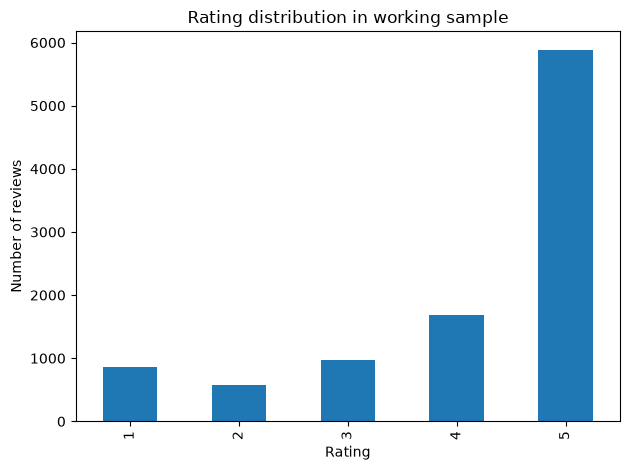

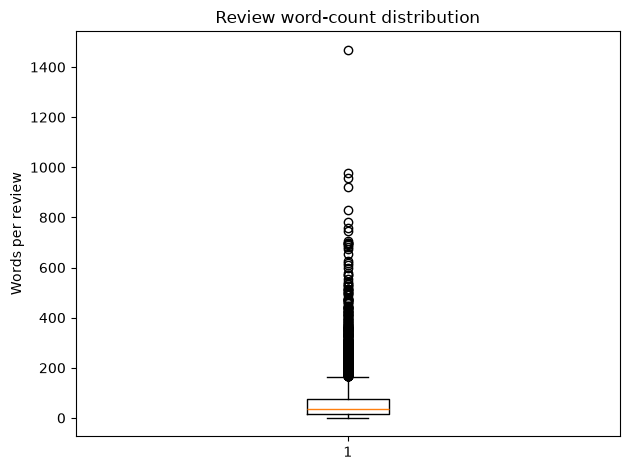

In [15]:
if "rating" in cleaned_master.columns:
    cleaned_master["rating"].value_counts(dropna=False).sort_index().plot(kind="bar")
    plt.title("Rating distribution in working sample")
    plt.xlabel("Rating")
    plt.ylabel("Number of reviews")
    plt.tight_layout()
    plt.show()

plt.figure()
plt.boxplot(
    cleaned_master["text_word_count"],
    orientation="vertical"
)
plt.title("Review word-count distribution")
plt.ylabel("Words per review")
plt.tight_layout()
plt.show()

## 17. Export outputs

The notebook creates:
- `amazon_beauty_cleaned_master_10k.csv`
- `amazon_beauty_nlp_ready_10k.csv`
- `amazon_beauty_quality_audit_10k.csv`
- `amazon_beauty_cleaning_log_10k.csv`

Missing image uploads are represented as `No image uploaded` in the cleaned output. Do not upload raw reviewer identifiers publicly unless there is a clear need and the dataset terms permit it. For public project sharing, consider excluding or hashing `user_id`.

In [16]:
cleaned_master.to_csv("amazon_beauty_cleaned_master_10k.csv", index=False)
nlp_ready.to_csv("amazon_beauty_nlp_ready_10k.csv", index=False)
audit.to_csv("amazon_beauty_quality_audit_10k.csv", index=False)
pd.DataFrame(cleaning_log).to_csv("amazon_beauty_cleaning_log_10k.csv", index=False)

print("Export completed.")

Export completed.


## 18. Limitations and next steps

1. This is a 10,000-row working sample from a much larger dataset; sample findings are not population estimates.
2. The source category is All Beauty and includes products beyond skincare.
3. Product metadata is needed to reliably distinguish cleansers, moisturizers, sunscreens, serums, and other product types.
4. Reviewers are self-selected; ratings and text may be affected by selection, brand, incentive, and platform biases.
5. English is the primary language described by the dataset card; language identification and multilingual handling should be considered before NLP.
6. Helpful votes and verified-purchase fields may be sparse or uneven; inspect their distributions before using them.
7. The dataset page presents license information inconsistently in different sections. Confirm the applicable license on the live dataset page before redistribution or reuse beyond the intended educational analysis.

## References

- Hugging Face dataset card: https://huggingface.co/datasets/jhan21/amazon-beauty-reviews-dataset
- Dataset CSV: https://huggingface.co/datasets/jhan21/amazon-beauty-reviews-dataset/blob/main/amazon_beauty_reviews_dataset.csv
- Hou et al. (2024), *Bridging Language and Items for Retrieval and Recommendation*, arXiv:2403.03952.